## [LAB-07] 추론통계

### 01_추론통계 개요

### #01 준비작업

1. 패키지 설치

In [1]:
!pip install --upgrade scipy
!pip install --upgrade jussam


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


2. 라이브러리 참조

In [2]:
from jussam import load_data
from helpers import *
from math import sqrt       # 루트 처리 함수
from scipy.stats import t   # t분포 객체

📦 연세대학교 주영아 교수가 제작한 라이브러리를 사용중입니다.
📧 Email(1): j.purplerose@yonsei.ac.kr
📧 Email(2): j.purplerose@gmail.com
📝 Website: https://juyounga.kr/
🔖 Version: 0.5.30


3. 데이터 가져오기

In [3]:
origin = load_data('height')
origin.head()

📚 어느 학교의 학년, 성별, 키에 대한 가상의 조사 자료 (출처: 방송통신대학교 통계학개론)


,학년,성별,키
0,1,남자,163
1,2,여자,154
2,1,남자,171
3,3,여자,160
4,4,남자,169


### #02 신뢰구간 더하기

1. 신뢰구간을 계산할 데이터

In [4]:
data = origin['키']
data.head()

0    163
1    154
2    171
3    160
4    169
Name: 키, dtype: int32

2. 신뢰수준 정의

In [5]:
clevel = 0.95

3. 샘플 사이즈

In [6]:
n = len(data)
n

36

4. 자유도

In [7]:
dof = n - 1
dof

35

5. 표본평균

In [8]:
sample_mean = data.mean()
sample_mean

np.float64(167.83333333333334)

6. 표본표준편차

In [9]:
sample_std = data.std()
sample_std

np.float64(7.315345905306578)

7. 표본표준오차

In [10]:
sample_std_error = sample_std / sqrt(n)
sample_std_error

np.float64(1.2192243175510964)

8. 신뢰구간
- scipy.stats 패키지의 t객체가 포함하는 interval(신뢰도, 자유도, loc=표본평균, scale=표본표준오차) 메서드를 사용한다.

In [11]:
cmin, cmax = t.interval(clevel, dof, loc=sample_mean,
                        scale=sample_std_error)
cmin, cmax

(np.float64(165.35817637995726), np.float64(170.30849028670943))

### #03 모듈 기능 확인

1. 연속형 데이터를 전달하는 형식
- 유의수준(clevel)은 생략시 0.95로 지정된다.

In [12]:
my_stats.ci(data, clevel=0.95)

(np.float64(165.35817637995726), np.float64(170.30849028670943))

2. 데이터 프레임과 컬럼 이름을 지정하는 형식

In [13]:
my_stats.ci(origin, columns='키', clevel=0.95)

(np.float64(165.35817637995726), np.float64(170.30849028670943))

### #04 신뢰구간 범위 시각화

1. 신뢰구간 직접 시각화하기
- KDE Plot에 신뢰구간을 세로 직선으로 추가한다.

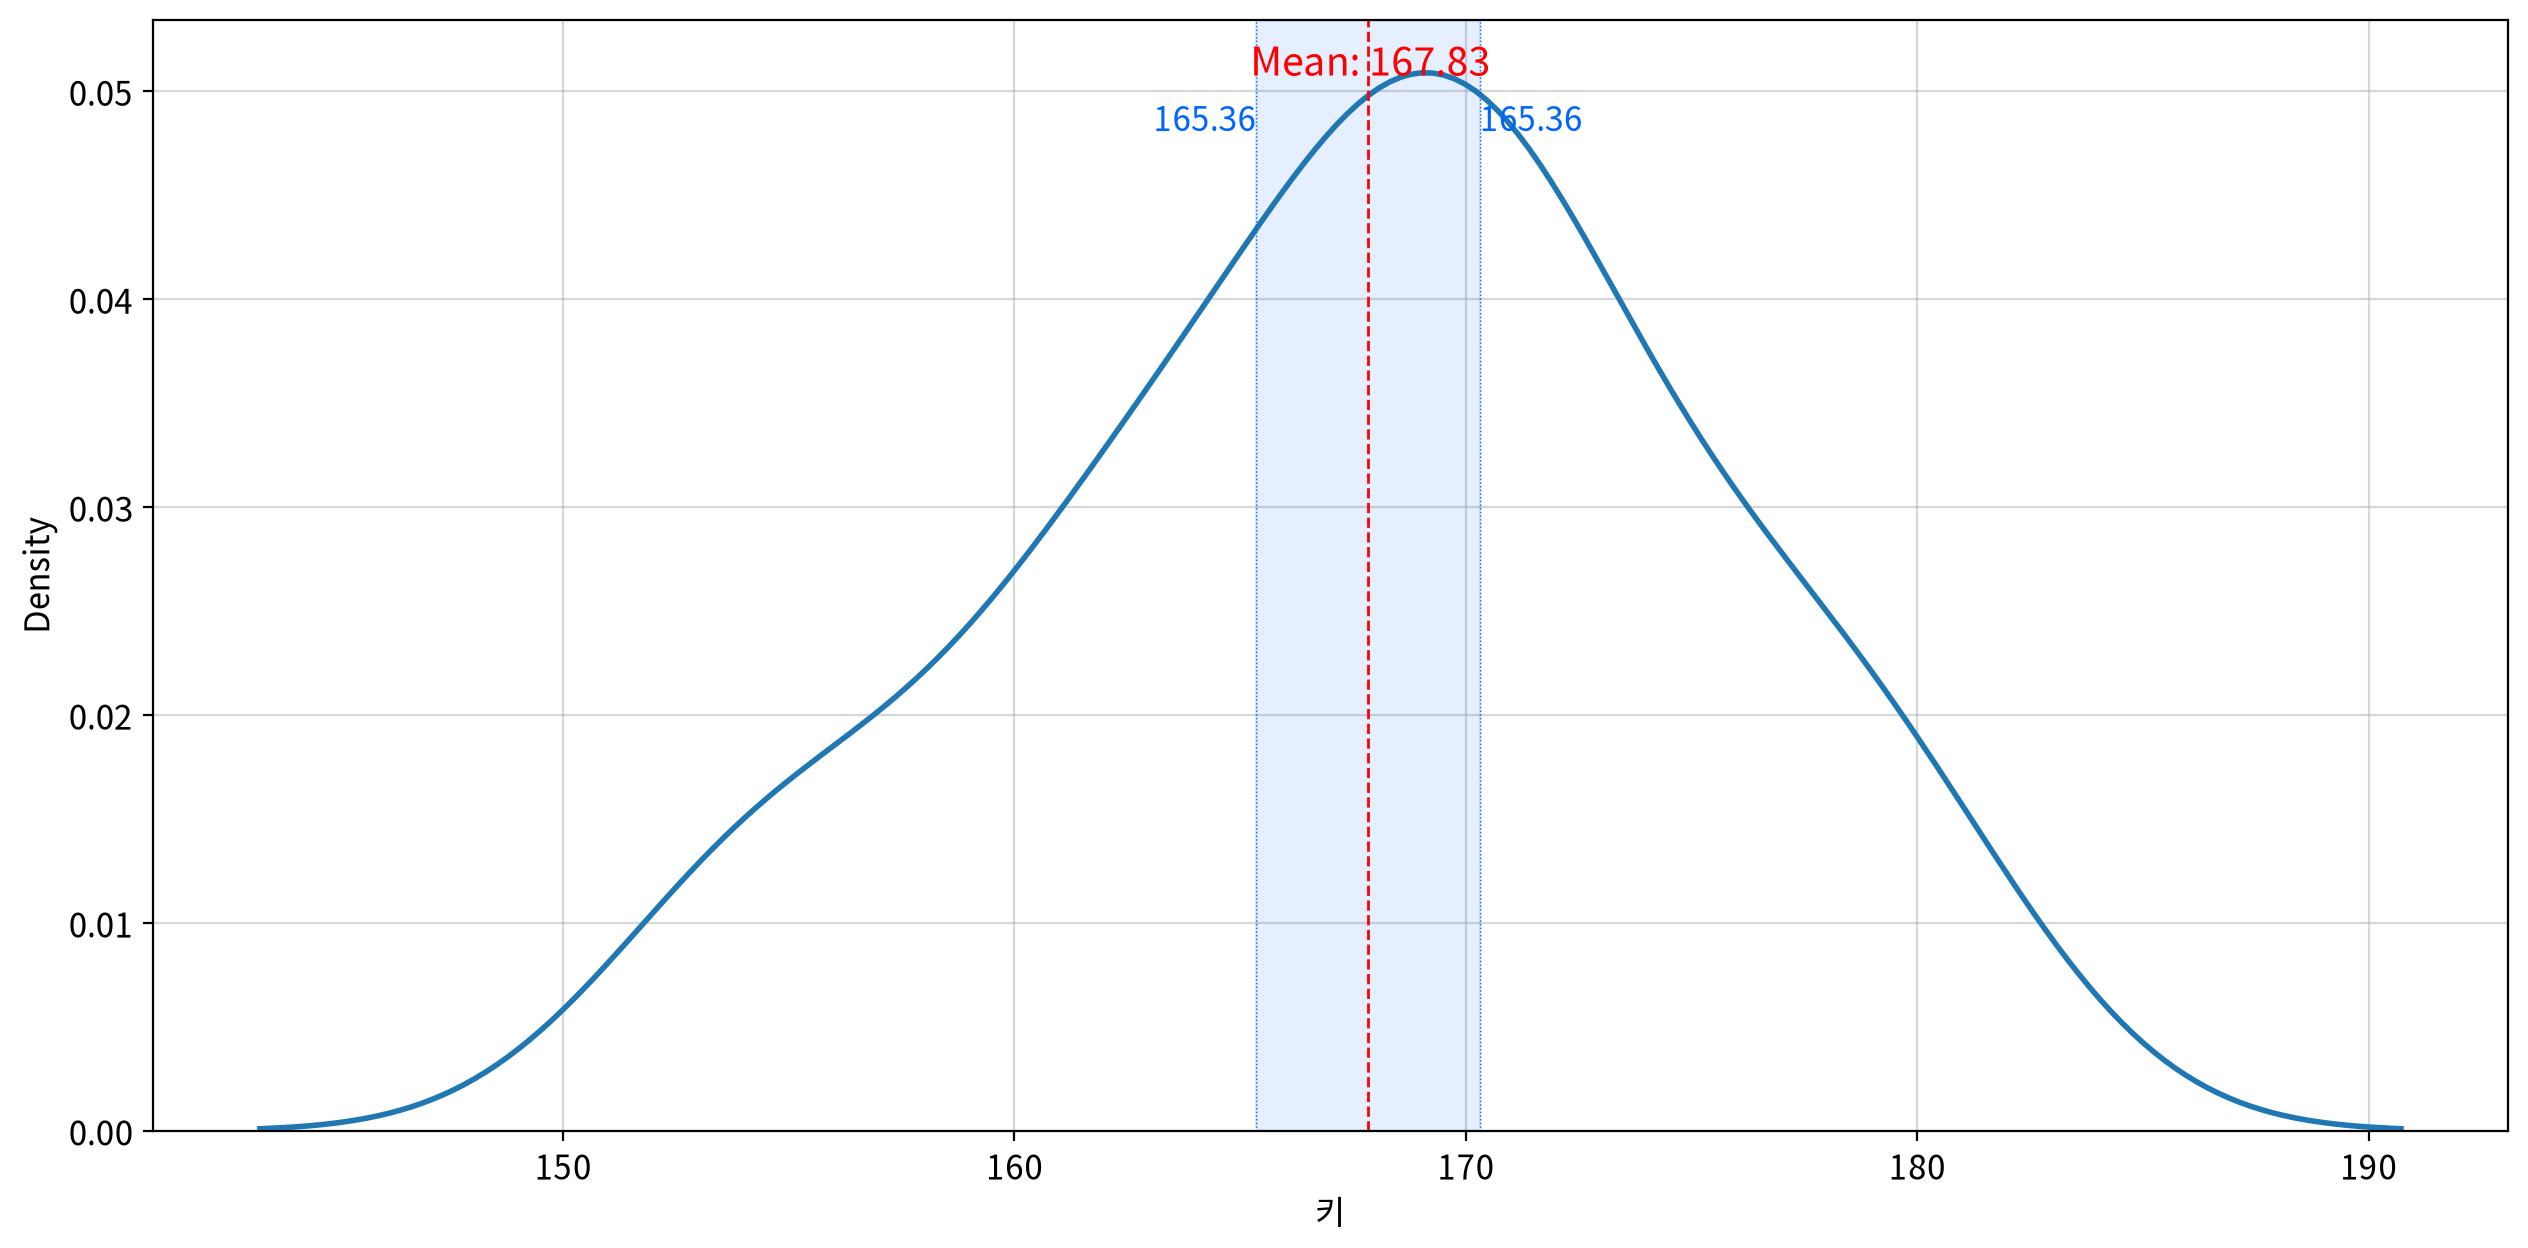

In [14]:
# ax 객체를 사용하여 추가적인 그래프 요소를 그릴 수 있도록 직접 초기화
fig, ax = my_plot.init()

# KDE 플롯 그리기 (평균선 포함)
my_plot.kdeplot(origin, '키', meanline=True, ax=ax)

# 신뢰구간 계산
cmin, cmax = my_stats.ci(origin, columns='키', clevel=0.95)

# 신뢰구간 범위에 대한 세로 직선 그리기 (cmin ~ cmax)
ax.axvline(cmin, linestyle=':', color='#0066ff', linewidth=0.5)
ax.axvline(cmax, linestyle=':', color='#0066ff', linewidth=0.5)

# 신뢰구간 범위에 대한 텍스트 추가
ax.text(cmin, ax.get_ylim()[1] * 0.9, f'{cmin:.2f}', color='#0066ff', ha='right')
ax.text(cmax, ax.get_ylim()[1] * 0.9, f'{cmin:.2f}', color='#0066ff', ha='left')

ymin, ymax = ax.get_ylim()      # 현재 축 범위 가져오기
ax.set_ylim(ymin, ymax)         # y축 범위 설정 (0부터 ymax까지)

# 신뢰구간 범위에 대한 영역 채우기 (cmin ~ cmax)
ax.fill_between([cmin, cmax], 0, ymax, alpha=0.1, color='#0066ff')

my_plot.show()

### #05 시각화 모듈 기능 확인

1. 단일 데이터에 대한 신뢰구간 확인

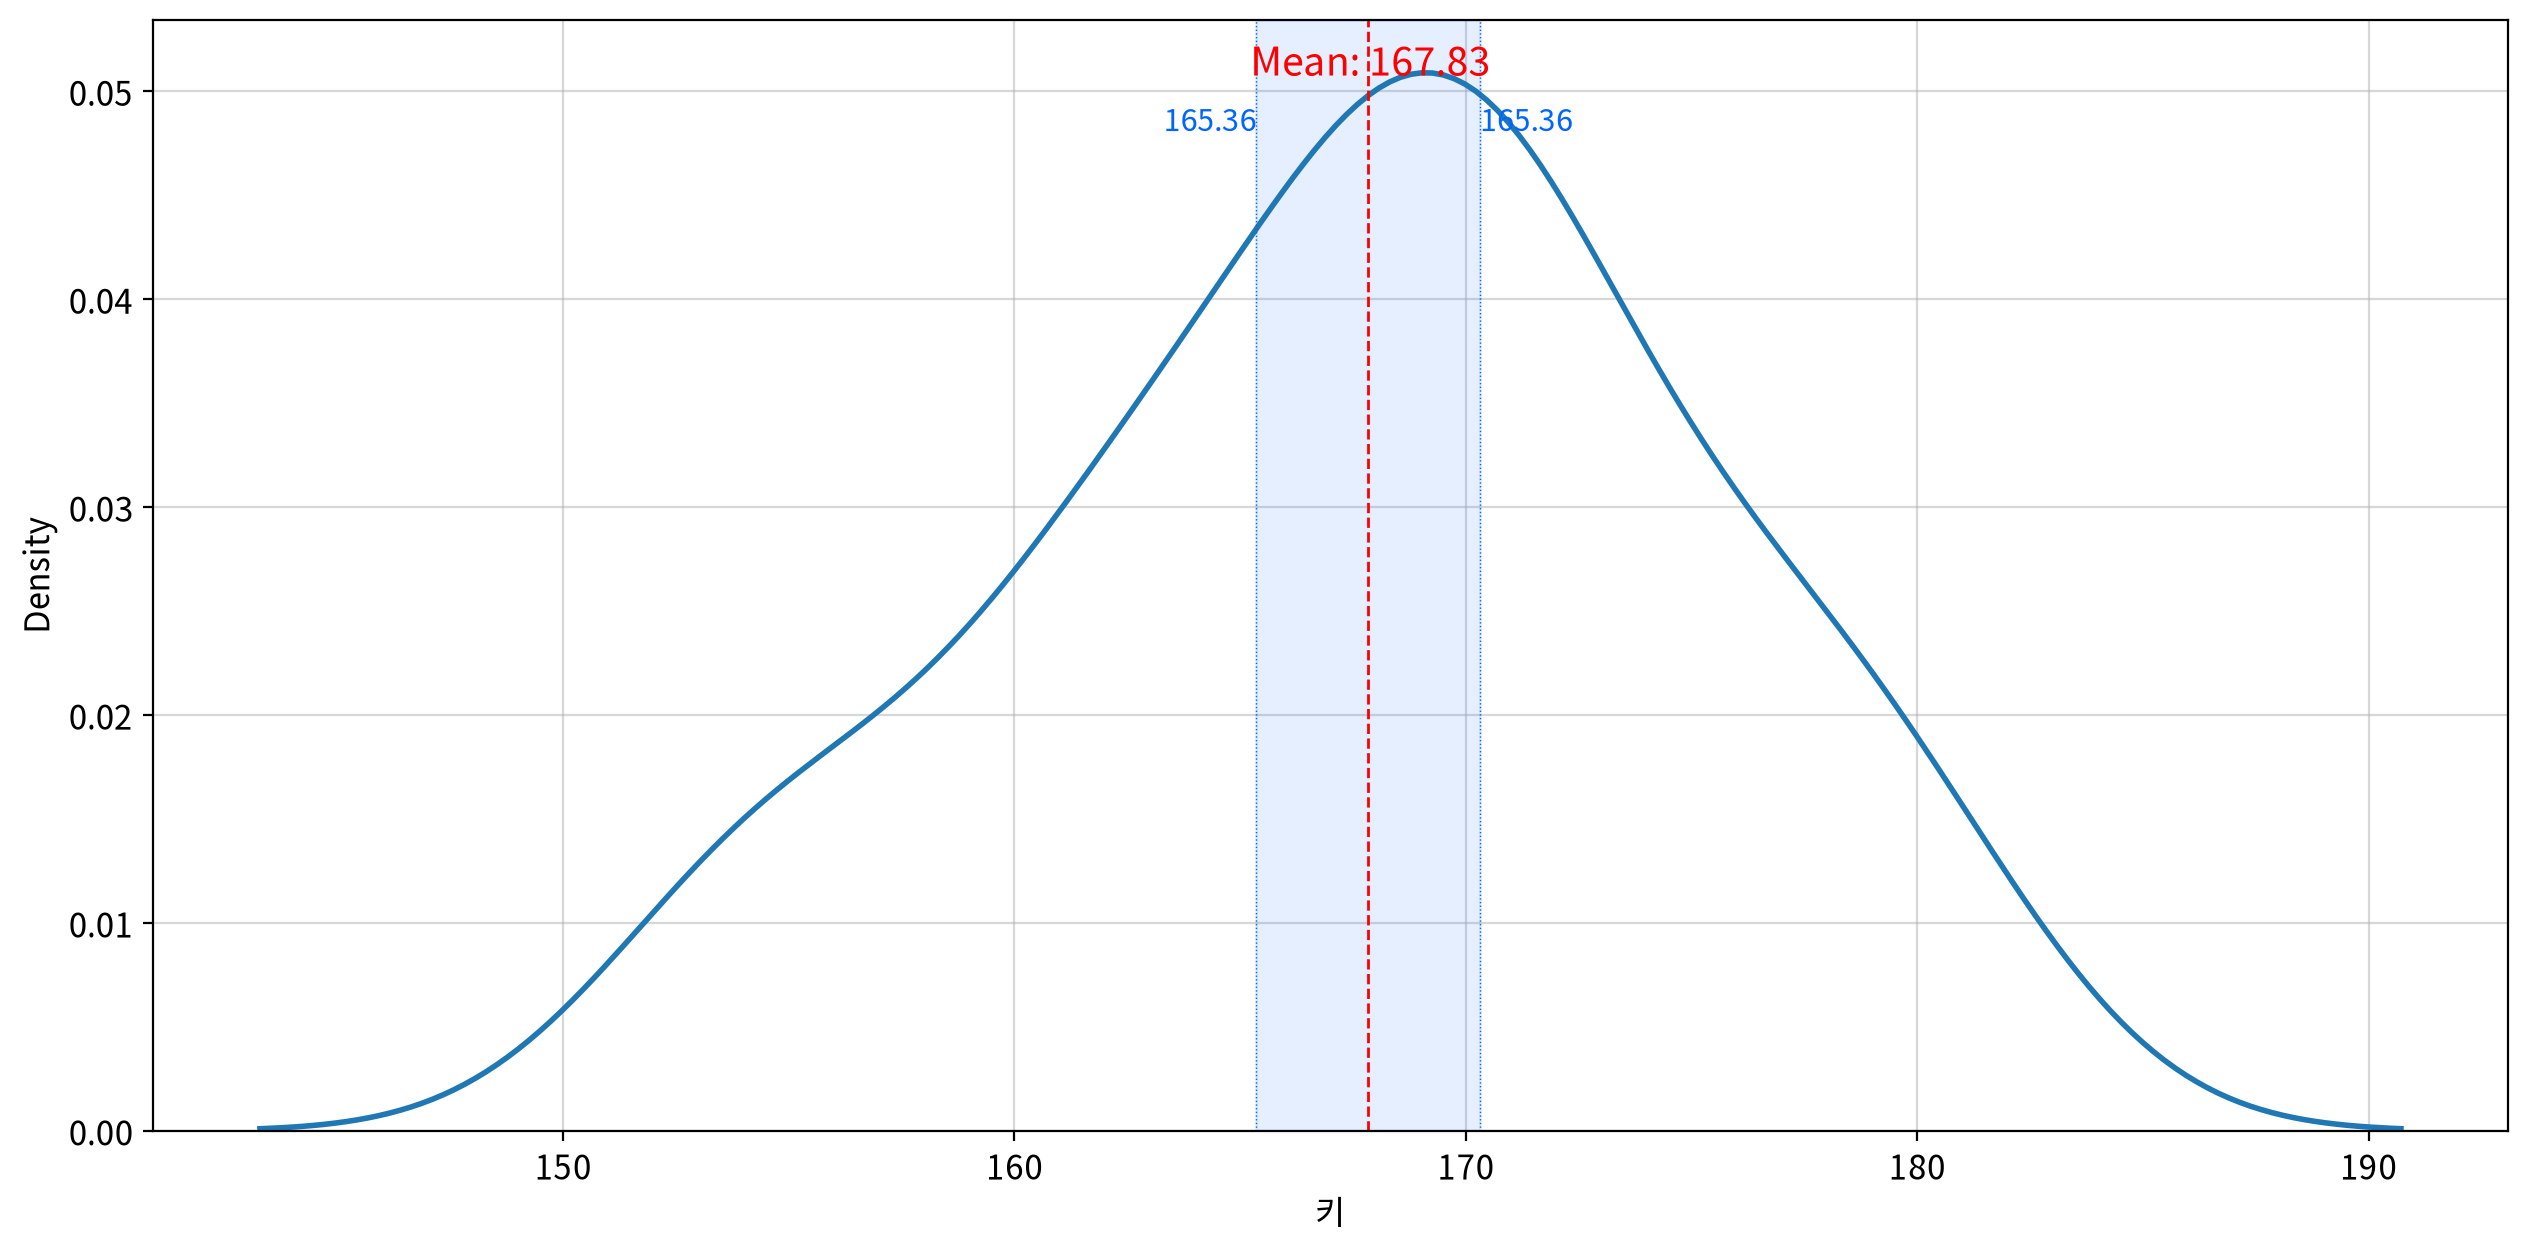

In [15]:
my_plot.kdeplot(origin, '키', meanline=True, clevel=0.95)

2. 범주별 신뢰구간 확인

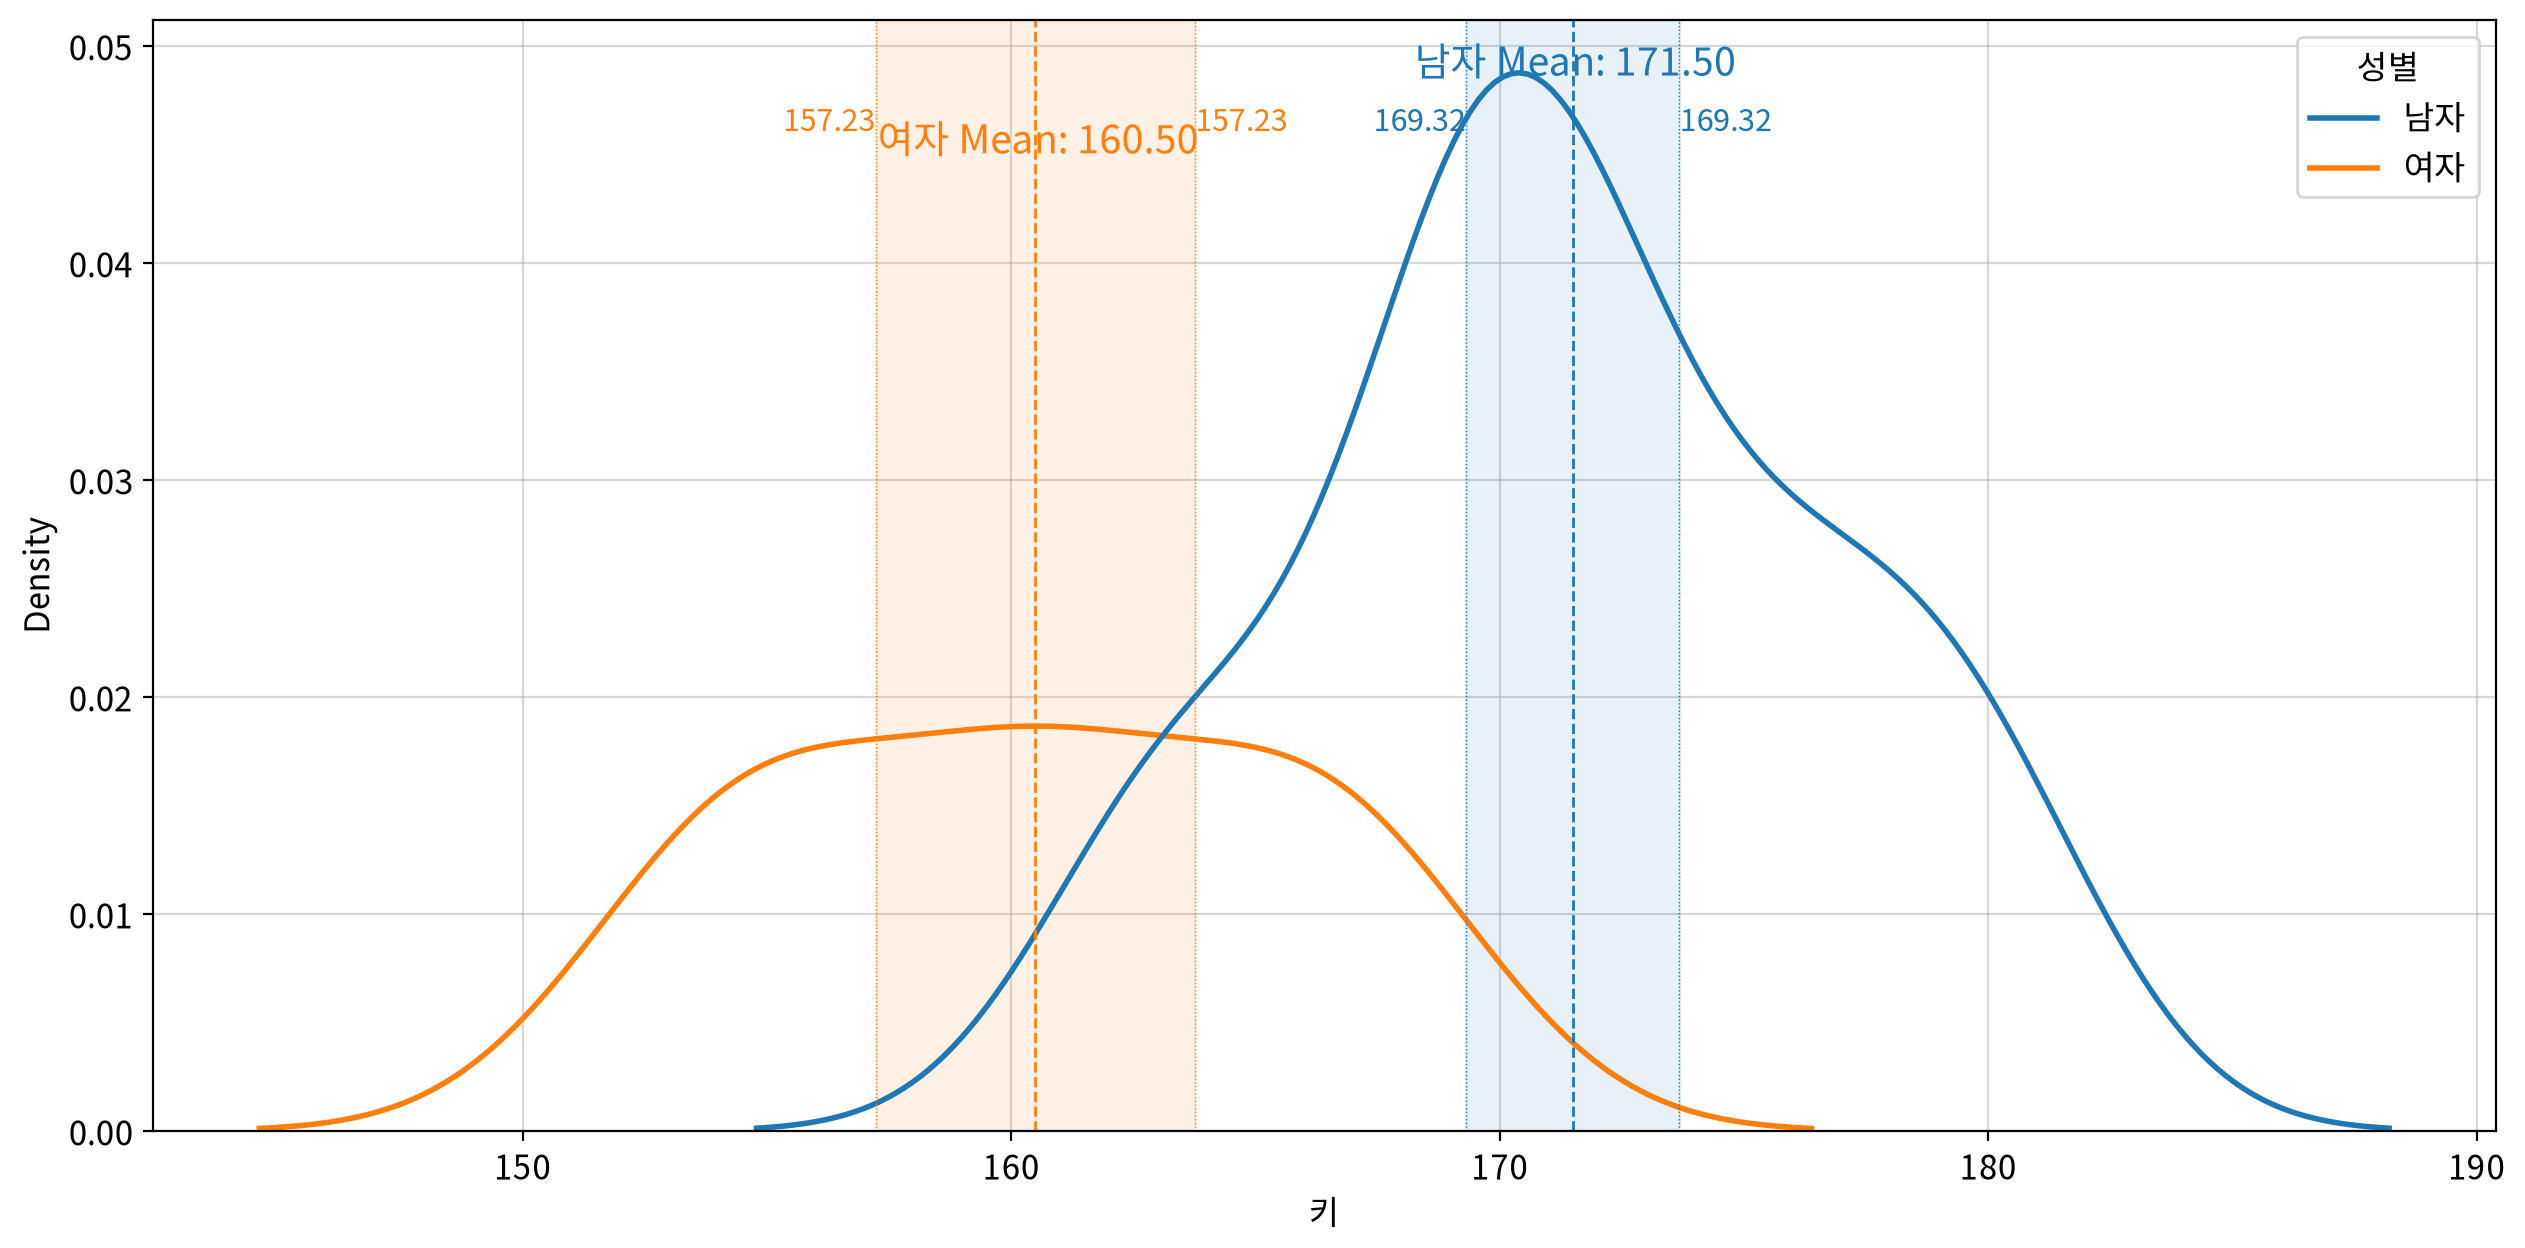

In [16]:
my_plot.kdeplot(origin, '키', hue='성별', meanline=True, clevel=0.95)

---

## 연습문제
### 평균 광고비-매출액 보고

□ 당신은 마케팅팀 데이터 분석가입니다.

- 본부장이 올해 12개월치 월별 광고비·매출 자료(ad_sales)를 통해 우리 회사의 평균 광고비와 매출이 어느 범위에 있는지 통계적으로 추정해야 합니다.

□ 문제

1. 본부장에게 보고할 월평균 광고비(백만원)의 95% 신뢰구간을 구하세요.
구간의 하한값과 상한값은 각각 얼마입니까?

2. 같은 방식으로 월평균 매출액(억원)의 95% 신뢰구간을 구하세요.
하한값과 상한값은 각각 얼마입니까?

3. 광고비와 매출액 분포를 하나의 그래프에 함께 시각화하세요.
그래프를 통해 표시되는 표본평균은 각각 얼마입니까?
(이를 위해 데이터를 long 형식으로 재배치해야 합니다.)

In [1]:
# 준비작업
from jussam import load_data
from helpers import *
from pandas import melt

📦 연세대학교 주영아 교수가 제작한 라이브러리를 사용중입니다.
📧 Email(1): j.purplerose@yonsei.ac.kr
📧 Email(2): j.purplerose@gmail.com
📝 Website: https://juyounga.kr/
🔖 Version: 0.5.30


In [18]:
# 데이터 가져오기
origin = load_data('ad_sales')
origin.head()

📚 어느 회사의 월별 광고액과 매출액을 조사한 가상의 데이터


,월,광고비(백만원),매출액(억원)
0,1월,2,100
1,2월,142,1690
2,3월,122,298
3,4월,130,390
4,5월,185,590


In [19]:
# 광고비 신뢰구간 구하기
my_stats.ci(origin, columns='광고비(백만원)', clevel=0.95)

(np.float64(107.5959743458858), np.float64(187.0706923207809))

In [20]:
# 매출액 신뢰구간 구하기
my_stats.ci(origin, columns='매출액(억원)', clevel=0.95)

(np.float64(265.73632131939956), np.float64(810.5970120139336))

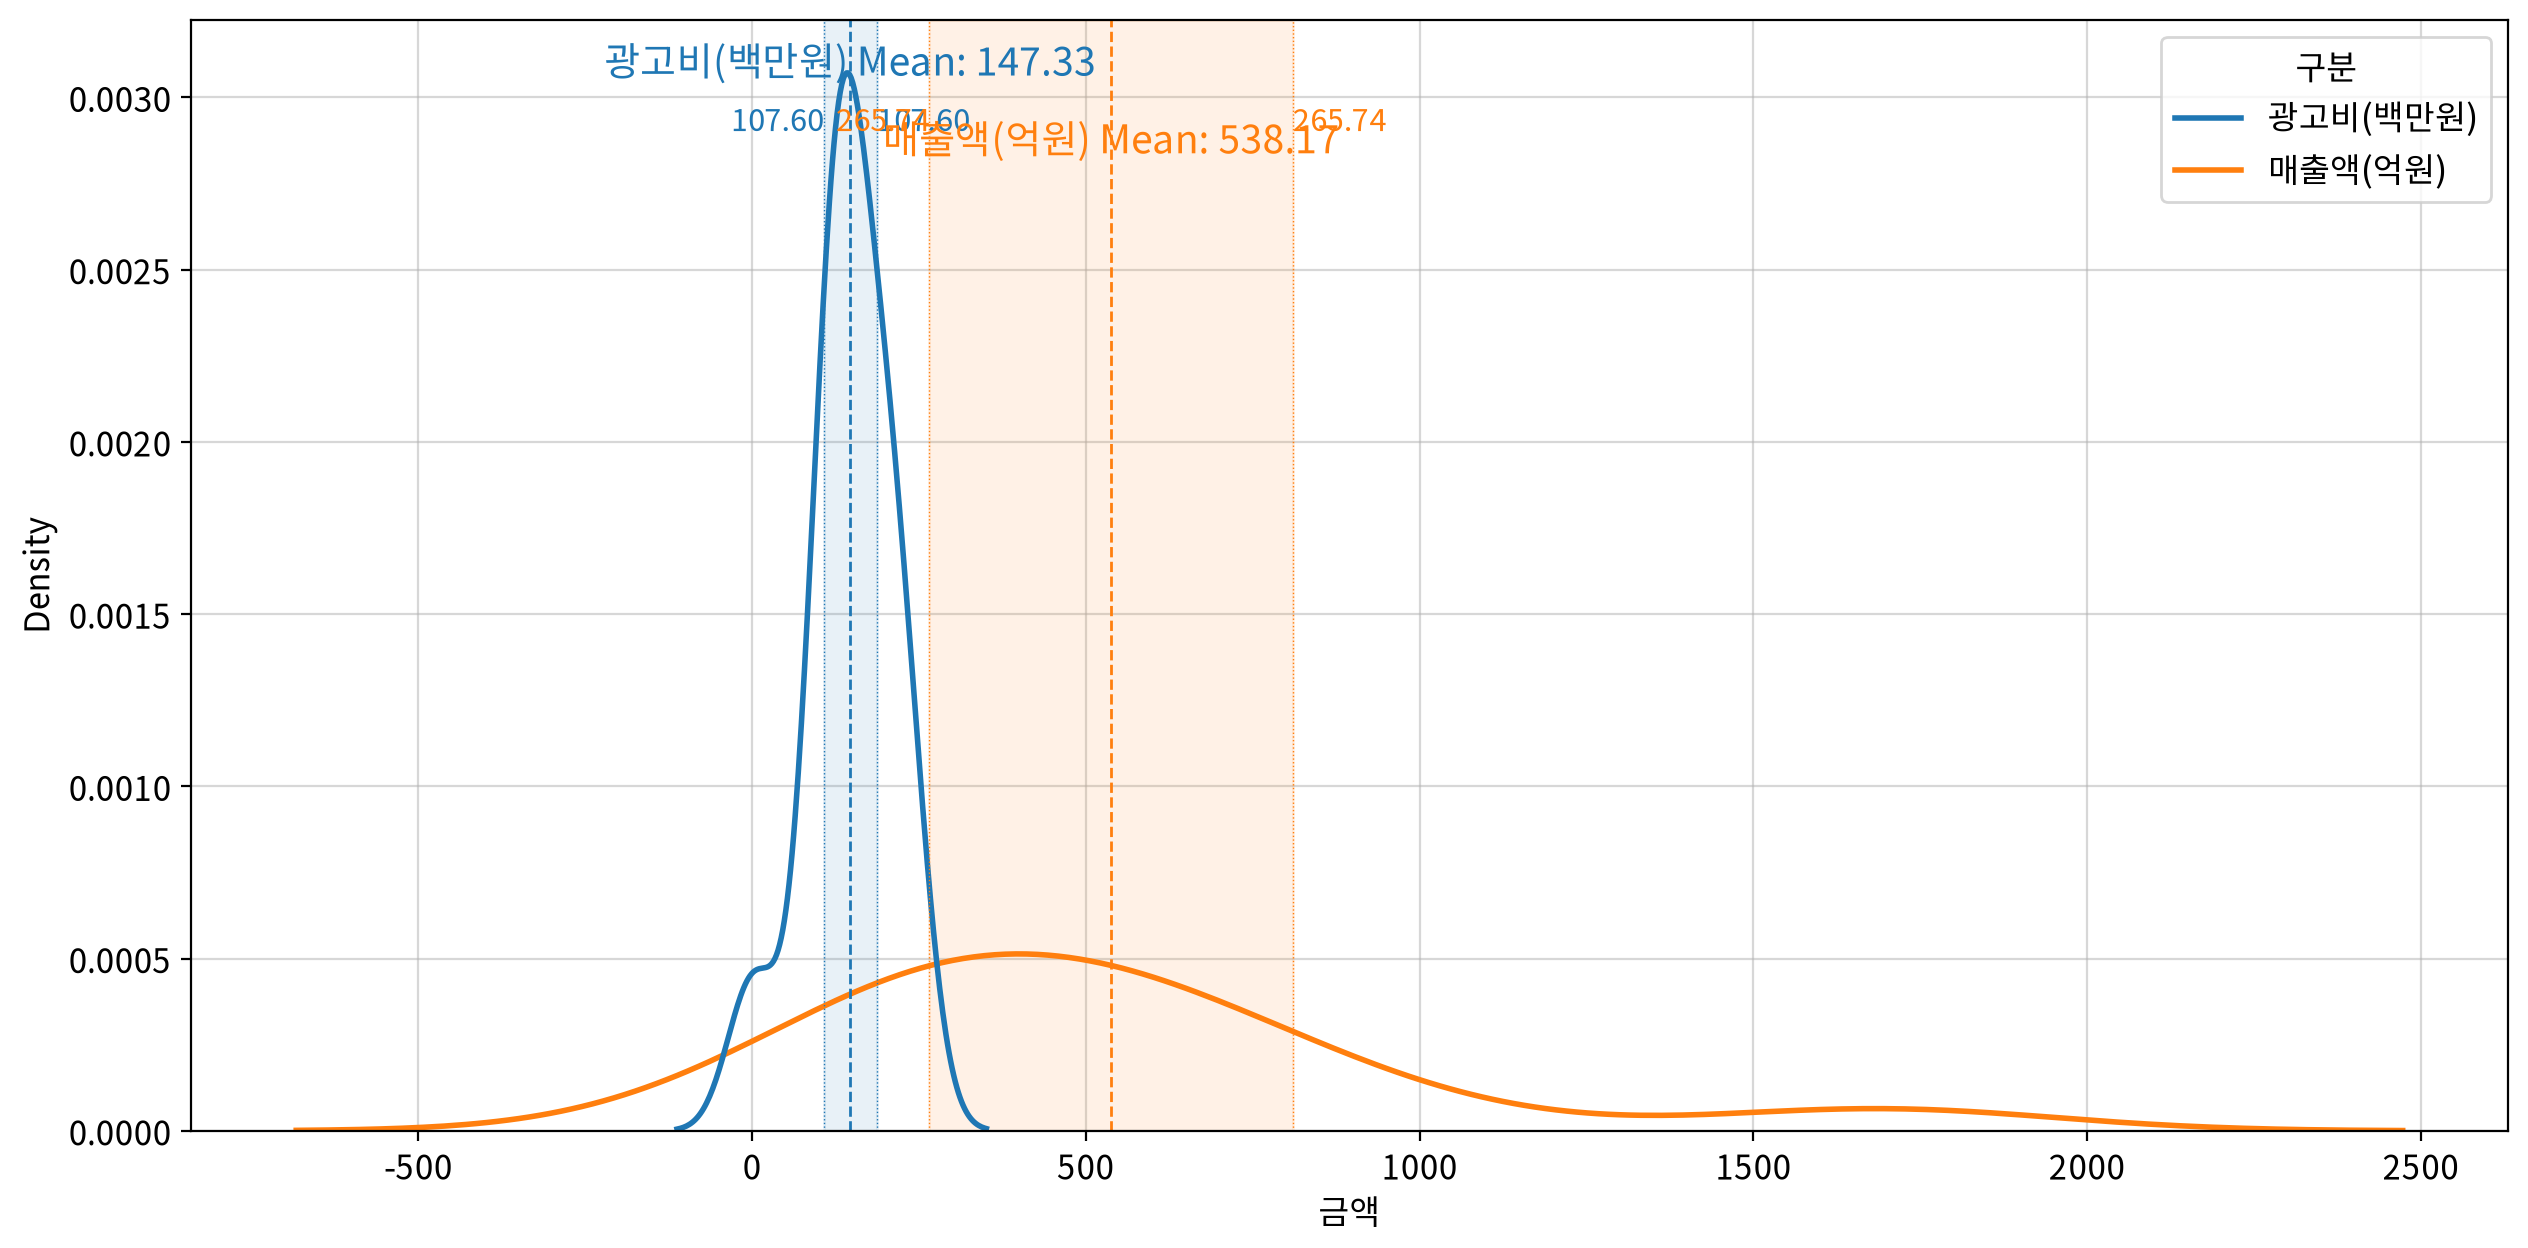

In [21]:
# 데이터 재구조화
mdf = melt(origin, id_vars=['월'], value_vars=['광고비(백만원)', '매출액(억원)'],
           var_name='구분', value_name='금액')

# 광고비와 매출액 분포를 함께 보기
my_plot.kdeplot(mdf, '금액', hue='구분', meanline=True, clevel=0.95)

1. 월평균 광고비(백만원)의 95% 신뢰구간
- 하한값: 107.60
- 상한값: 187.07

2. 월평균 매출액(억원)의 95% 신뢰구간
- 하한값: 265.74
- 상한값: 810.60

3. 광고비와 매출액 분포 그래프를 통해 표시되는 표본평균
- 광고비: 147.33
- 매출액: 538.17